# Binocular Rivalry Perceptual Consciousness: Hierarchical Representational Testing Framework

This notebook implements a unified, hierarchical representational testing framework designed to evaluate how different spatial, spectral, temporal, and network-connectivity representations of EEG signals affect decoding performance for **Binocular Rivalry (BR) perceptual consciousness states**.

## 📋 Hierarchical Experiments Structure

To build a robust and scientifically sound EEG decoding framework, we avoid ad-hoc parameter tuning and instead test progressive representational hypotheses:

1. **Stage 1: Preprocessing & Normalization Ablation**
   - Evaluates if Z-scoring destroys absolute amplitude/power markers. Compares No normalization, Train-fold Z-scoring, Subject-level Z-scoring (non-leaking), and Trial-wise Z-scoring.
2. **Stage 2: Representation Diagnostics (Spatial, Time, Spectral) - Run on Both Tasks**
   - Isolates where information is located (Cluster channels, Paper ROI channels, 29 channels, 60 channels; conflict window vs. full epoch; theta, alpha, theta+alpha, broadband) using a Riemannian baseline classifier.
3. **Stage 3: Classical Machine Learning Branch**
   - Compares classifiers (LR, LDA, Random Forest, XGBoost, LightGBM) using envelope/power-based features.
4. **Stage 4: Classical Spatial Baselines**
   - Evaluates Broadband CSP + LDA and Filter Bank CSP (FBCSP) + LDA.
5. **Stage 5: Connectivity & Network Structure Representations - Run on Both Tasks**
   - Computes PLV/coherence connectivity networks in Theta/Alpha and trains classifiers on network connectivity tensors.
6. **Stage 6: Focused Deep Learning Branch**
   - EEGNet Clustering: Nested cluster selection inside CV splits under 4 ablation variants.
   - ST-GNN: Compares distance graph, functional graph (PLV from training split), and GNN with flat DE features.
7. **Stage 7: Pretrained Models & Transfer Learning**
   - Pretrained LaBraM: Linear Probe vs. LoRA fine-tuning (rank, dropout, weight decay).
8. **Stage 8: Generalization Tests**
   - Leave-One-Subject-Out (LOSO) CV, few-shot subject adaptation, and cross-condition check ($C$ vs. $IP$ -> $IM$ vs. $IP$).
9. **Stage 9: Control Tests (Subject-Identification Control)**
   - Subject ID decoding vs. condition decoding accuracy to measure individual-specific variance.

In [ ]:
import os
import sys
import warnings
from pathlib import Path
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from scipy.signal import hilbert, welch
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
)
from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace

# Add src to path
src_path = Path("c:/Users/nils/Documents/Universitat/TFG/src")
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

from br_analysis import (
    detect_project_paths,
    get_task_config,
    load_raw_epoch_dataset,
    RawEpochSpec,
    FusedBandSpec,
    load_fused_band_dataset,
    COMMON_BAND_RANGES,
    TARGET_BANDS_CLUSTERS,
    temporal_band_features,
    electrode_distance_adjacency,
)
from br_analysis.experiments import chronological_group_labels, stratified_group_splits
from br_analysis.torch_training import (
    TorchTrainConfig,
    cross_validate_torch_model,
    standardize_train_test,
    build_dataloader,
    _evaluate,
)
from br_analysis.pretrained import prepare_lora_backbone, load_backbone_weights, BackboneClassifier

mne.set_log_level("WARNING")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Experiment execution control flags
RUN_EXPERIMENTS = {
    "experiment1_preprocessing": True,
    "experiment2_diagnostics": True,
    "experiment3_classical_ml": True,
    "experiment4_spatial_baselines": True,
    "experiment5_connectivity": True,
    "experiment6_deep_learning": True,
    "experiment7_pretrained_models": True,
    "experiment8_joint_search": True,
    "experiment9_dl_tuning": True,
    "experiment10_generalization": True,
    "experiment11_subject_id_control": True,
}

print("Imports and settings loaded successfully.")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Imports and settings loaded successfully.
Using device: cpu


In [59]:
paths = detect_project_paths("experiments")

# 1. Load C vs IP task
task_c = get_task_config("c_vs_ip", paths.analysis_root)
spec_broadband = RawEpochSpec(picks=None, bandpass=(1.0, 40.0), resample_sfreq=128.0)
dataset_c = load_raw_epoch_dataset(paths, task_c, spec_broadband, verbose=False)

# 2. Load IM vs IP task
task_im = get_task_config("im_vs_ip", paths.analysis_root)
dataset_im = load_raw_epoch_dataset(paths, task_im, spec_broadband, verbose=False)

X_c = np.asarray(dataset_c.X, dtype=np.float32)
y_c = np.asarray(dataset_c.y, dtype=np.int64)
subjects_c = np.asarray(dataset_c.subjects, dtype=object)

X_im = np.asarray(dataset_im.X, dtype=np.float32)
y_im = np.asarray(dataset_im.y, dtype=np.int64)
subjects_im = np.asarray(dataset_im.subjects, dtype=object)

# Select the 10 standard cohort subjects for consistent comparative analysis
NUM_SUBJECTS = 10
target_subjects = list(set(dataset_c.subjects))
target_subjects = [sub for sub in target_subjects if sub in dataset_im.subjects][:NUM_SUBJECTS]


print(f"Cohort size: {NUM_SUBJECTS}")
print(f"Selected subjects: {target_subjects}")

# Slices for C vs IP
X_subs_c = {sub: X_c[subjects_c == sub] for sub in target_subjects}
y_subs_c = {sub: y_c[subjects_c == sub] for sub in target_subjects}

# Slices for IM vs IP
X_subs_im = {sub: X_im[subjects_im == sub] for sub in target_subjects}
y_subs_im = {sub: y_im[subjects_im == sub] for sub in target_subjects}

for sub in target_subjects:
    print(f"  Subject {sub}: {len(y_subs_c[sub])} trials (C vs IP), {len(y_subs_im[sub])} trials (IM vs IP)")

Cohort size: 10
Selected subjects: ['P065', 'P051', 'P013', 'P002', 'P017', 'P003', 'P061', 'P057', 'P067', 'P062']
  Subject P065: 444 trials (C vs IP), 210 trials (IM vs IP)
  Subject P051: 218 trials (C vs IP), 218 trials (IM vs IP)
  Subject P013: 318 trials (C vs IP), 318 trials (IM vs IP)
  Subject P002: 206 trials (C vs IP), 206 trials (IM vs IP)
  Subject P017: 226 trials (C vs IP), 226 trials (IM vs IP)
  Subject P003: 382 trials (C vs IP), 234 trials (IM vs IP)
  Subject P061: 304 trials (C vs IP), 270 trials (IM vs IP)
  Subject P057: 240 trials (C vs IP), 240 trials (IM vs IP)
  Subject P067: 152 trials (C vs IP), 152 trials (IM vs IP)
  Subject P062: 296 trials (C vs IP), 182 trials (IM vs IP)


### Experiment 1: Preprocessing & Normalization Ablation

We compare normalization methods strictly fit inside temporal cross-validation folds to prevent temporal data leakage:
1. **No Normalization**: Voltage scaled to microvolts ($X \times 1e6$).
2. **Trial-wise Normalization**: Z-score calculated per trial, channel, and time axis.
3. **Global Train-Fold Normalization**: Mean/std fit on the training fold across all trials, and applied to test.
4. **Subject-level Normalization**: Mean/std fit *only* on the training trials of a subject, and applied to both train and test trials.
5. **Standard Scaler Normalization**: StandardScaler applied to 2D trial-channel-time data, fit on training fold and applied to test fold.
6. **Robust Scaler Normalization**: RobustScaler applied to 2D trial-channel-time data, fit on training fold and applied to test fold.


=== Normalization Ablation Summary (C vs IP) ===
        Normalization  Accuracy  Std Dev
Global Fold Z-scoring  0.558164 0.057376
        Subject-level  0.558164 0.057376
     No Normalization  0.557832 0.059361
      Standard Scaler  0.555210 0.062736
        Robust Scaler  0.552726 0.056145
 Trial-wise Z-scoring  0.544510 0.053048


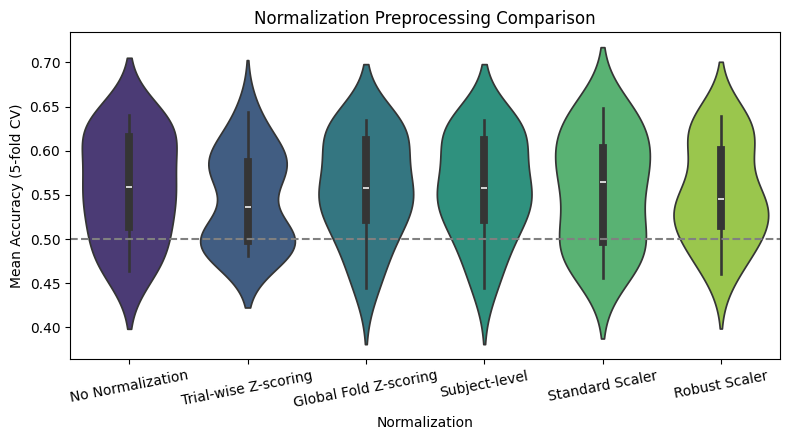

Pairwise t-test: No Normalization vs Trial-wise Z-scoring | t=1.275, p=0.218
Pairwise t-test: No Normalization vs Global Fold Z-scoring | t=-0.088, p=0.931
Pairwise t-test: No Normalization vs Subject-level | t=-0.088, p=0.931
Pairwise t-test: No Normalization vs Standard Scaler | t=0.614, p=0.546
Pairwise t-test: No Normalization vs Robust Scaler | t=0.946, p=0.356
Pairwise t-test: Trial-wise Z-scoring vs Global Fold Z-scoring | t=-1.419, p=0.172
Pairwise t-test: Trial-wise Z-scoring vs Subject-level | t=-1.419, p=0.172
Pairwise t-test: Trial-wise Z-scoring vs Standard Scaler | t=-0.938, p=0.360
Pairwise t-test: Trial-wise Z-scoring vs Robust Scaler | t=-0.752, p=0.461
Pairwise t-test: Global Fold Z-scoring vs Subject-level | t=nan, p=nan
Pairwise t-test: Global Fold Z-scoring vs Standard Scaler | t=0.492, p=0.628
Pairwise t-test: Global Fold Z-scoring vs Robust Scaler | t=0.729, p=0.475
Pairwise t-test: Subject-level vs Standard Scaler | t=0.492, p=0.628
Pairwise t-test: Subject-leve

In [75]:
def standardize_trial_wise(X_train, X_test):
    def _std(X):
        mean = X.mean(axis=-1, keepdims=True)
        std = X.std(axis=-1, keepdims=True)
        std = np.maximum(std, 1e-6)
        return (X - mean) / std

    return _std(X_train), _std(X_test)


def standardize_global_fold(X_train, X_test):
    mean = X_train.mean(axis=(0, 2), keepdims=True)
    std = X_train.std(axis=(0, 2), keepdims=True)
    std = np.maximum(std, 1e-6)
    return (X_train - mean) / std, (X_test - mean) / std


def standardize_subject_wise(X_train, X_test):
    mean = X_train.mean(axis=(0, 2), keepdims=True)
    std = X_train.std(axis=(0, 2), keepdims=True)
    std = np.maximum(std, 1e-6)
    return (X_train - mean) / std, (X_test - mean) / std


def standardize_robust_scaler(X_train, X_test):
    n_trials, n_channels, n_times = X_train.shape
    X_train_2d = X_train.reshape(n_trials, -1)
    X_test_2d = X_test.reshape(X_test.shape[0], -1)
    from sklearn.preprocessing import RobustScaler

    scaler = RobustScaler()
    X_train_scaled = scaler.fit_transform(X_train_2d)
    X_test_scaled = scaler.transform(X_test_2d)
    return X_train_scaled.reshape(n_trials, n_channels, n_times), X_test_scaled.reshape(
        X_test.shape[0], n_channels, n_times
    )


def standardize_standard_scaler(X_train, X_test):
    n_trials, n_channels, n_times = X_train.shape
    X_train_2d = X_train.reshape(n_trials, -1)
    X_test_2d = X_test.reshape(X_test.shape[0], -1)
    from sklearn.preprocessing import StandardScaler

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_2d)
    X_test_scaled = scaler.transform(X_test_2d)
    return X_train_scaled.reshape(n_trials, n_channels, n_times), X_test_scaled.reshape(
        X_test.shape[0], n_channels, n_times
    )


def standardize_none(X_train, X_test):
    return X_train * 1e6, X_test * 1e6


cache_file = paths.tables_dir / "exp1_preprocessing_results.csv"


if RUN_EXPERIMENTS["experiment1_preprocessing"]:
    modes = {
        "No Normalization": standardize_none,
        "Trial-wise Z-scoring": standardize_trial_wise,
        "Global Fold Z-scoring": standardize_global_fold,
        "Subject-level": standardize_subject_wise,
        "Standard Scaler": standardize_standard_scaler,
        "Robust Scaler": standardize_robust_scaler,
    }

    results = []
    for sub in target_subjects:
        X_sub, y_sub = X_subs_c[sub], y_subs_c[sub]
        t_mask = (dataset_c.times >= 0.375) & (dataset_c.times <= 1.242)
        X_c_crop = X_sub[..., t_mask]

        splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)

        for mode_name, norm_fn in modes.items():
            print(f"Processing {mode_name}...")
            accs = []
            for train_idx, test_idx in splits:
                print(f"  Split: {train_idx.shape[0]} train, {test_idx.shape[0]} test")
                X_tr, X_te = norm_fn(X_c_crop[train_idx], X_c_crop[test_idx])
                y_tr, y_te = y_sub[train_idx], y_sub[test_idx]

                pipeline = make_pipeline(
                    Covariances(estimator="oas"), TangentSpace(metric="riemann"), LDA(solver="lsqr", shrinkage="auto")
                )
                pipeline.fit(X_tr, y_tr)
                accs.append(accuracy_score(y_te, pipeline.predict(X_te)))
            results.append({"Subject": sub, "Normalization": mode_name, "Accuracy": np.mean(accs)})

    df_res = pd.DataFrame(results)
    df_res.to_csv(cache_file, index=False)

try:
    df_res = pd.read_csv(cache_file)
    # Aggregate results
    summary = df_res.groupby("Normalization")["Accuracy"].mean().reset_index()
    summary["Std Dev"] = df_res.groupby("Normalization")["Accuracy"].std().values
    summary = summary.sort_values("Accuracy", ascending=False)
    print("\n=== Normalization Ablation Summary (C vs IP) ===")
    print(summary.to_string(index=False))

    # Violin plot
    plt.figure(figsize=(8, 4.5))
    sns.violinplot(data=df_res, x="Normalization", y="Accuracy", palette="viridis", hue="Normalization", inner="box")
    plt.axhline(0.5, linestyle="--", color="gray", label="Chance")
    plt.title("Normalization Preprocessing Comparison")
    plt.ylabel("Mean Accuracy (5-fold CV)")
    plt.xticks(rotation=11)
    plt.tight_layout()
    plt.savefig(paths.figures_dir / "experiment1_normalization_comparison.png", dpi=300)
    plt.show()

    # pairwise t-tests
    from scipy.stats import ttest_rel

    norm_types = df_res["Normalization"].unique()
    for i in range(len(norm_types)):
        for j in range(i + 1, len(norm_types)):
            group1 = df_res[df_res["Normalization"] == norm_types[i]]["Accuracy"]
            group2 = df_res[df_res["Normalization"] == norm_types[j]]["Accuracy"]
            t_stat, p_val = ttest_rel(group1, group2)
            print(f"Pairwise t-test: {norm_types[i]} vs {norm_types[j]} | t={t_stat:.3f}, p={p_val:.3f}")

except FileNotFoundError:
    print("Experiment 1 results not found. Please run the experiment to generate results.")

All normalization methods achieved similar results, with `Trial-wise Z-scoring` performing slightly worse. StandardScaler had the highest variance, and RobustScaler performed slightly worse than StandardScaler, suggesting that outliers may not be a major issue in this dataset. The results indicate that the choice of normalization method does not significantly impact decoding performance, but future experiments will see if this holds true for more complex representations and classifiers.

### Experiment 2: Representation Diagnostics

We run this diagnostic on **both tasks (`c_vs_ip` and `im_vs_ip`)** using the locked Riemannian classifier to determine where the information is located before spending days training deep neural network backbones.

We evaluate three scopes of representation:
1. **Spatial scope**:
   - *Paper ROI channels*: P7, P8, PO7, PO3, POz, PO4, PO8, O1, Oz, O2 for alpha; Fz, FCz, Cz for theta (13 channels).
   - *Temporal cluster channels*: Frontomedial cluster channels (9 channels).
   - *Parieto-occipital cluster channels*: Parieto-occipital cluster channels (13 channels).
   - *Cluster channels*: Parieto-occipital + frontomedial cluster channels (22 channels).
   - *29 channels*: Expanded clustering layout.
   - *60 channels*: Agnostic/all channels.
2. **Time scope**:
   - *First 500ms*: 0.0s to 0.5s.
   - *Middle 500ms*: 0.5s to 1.0s.
   - *Last 500ms*: 1.0s to 1.5s.
   - *Conflict window*: 0.375s to 1.242s.
   - *Full epoch*: 0.0s to 1.5s.
3. **Spectral scope**:
   - *Theta* (5–7 Hz)
   - *Alpha* (8–12 Hz)
   - *Theta+Alpha* (5–12 Hz)
   - *Broadband* (1–40 Hz)


=== Spatial Diagnostics Summary ===
                        Config     Task     mean      std
Parieto-Occipital Cluster (13) IM vs IP 0.549418 0.054670
                Paper ROI (13) IM vs IP 0.531417 0.075592
             All Channels (60) IM vs IP 0.525380 0.096856
         Cluster channels (22) IM vs IP 0.517748 0.081818
          Temporal Cluster (9) IM vs IP 0.508296 0.085779
                Paper ROI (13)  C vs IP 0.576865 0.047575
             All Channels (60)  C vs IP 0.557705 0.054772
Parieto-Occipital Cluster (13)  C vs IP 0.552459 0.069919
         Cluster channels (22)  C vs IP 0.544662 0.044819
          Temporal Cluster (9)  C vs IP 0.523180 0.047762


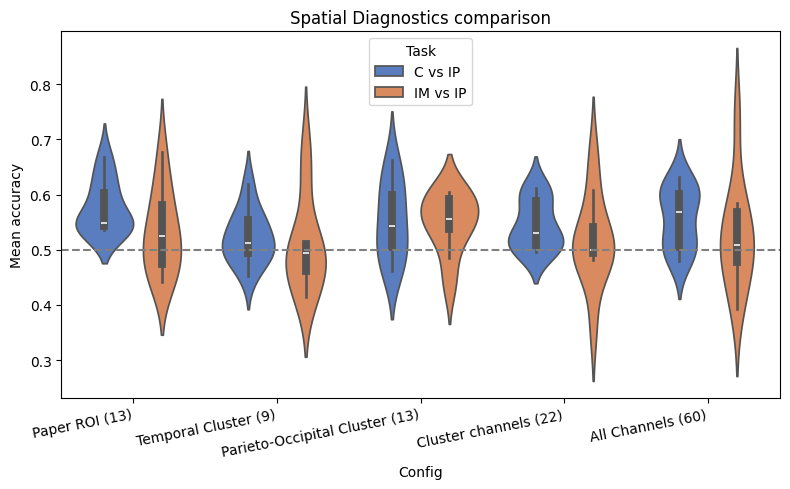


=== Temporal Diagnostics Summary ===
                        Config     Task     mean      std
         Full Epoch (0.0-1.5s) IM vs IP 0.525380 0.096856
       First window (0.0-0.5s) IM vs IP 0.525091 0.083757
      Second window (0.5-1.0s) IM vs IP 0.521878 0.071400
Conflict Window (0.375-1.242s) IM vs IP 0.514475 0.078185
       Third window (1.0-1.5s) IM vs IP 0.499333 0.054053
Conflict Window (0.375-1.242s)  C vs IP 0.570412 0.048141
       Third window (1.0-1.5s)  C vs IP 0.563345 0.041637
         Full Epoch (0.0-1.5s)  C vs IP 0.557705 0.054772
      Second window (0.5-1.0s)  C vs IP 0.547217 0.065335
       First window (0.0-0.5s)  C vs IP 0.492061 0.030426


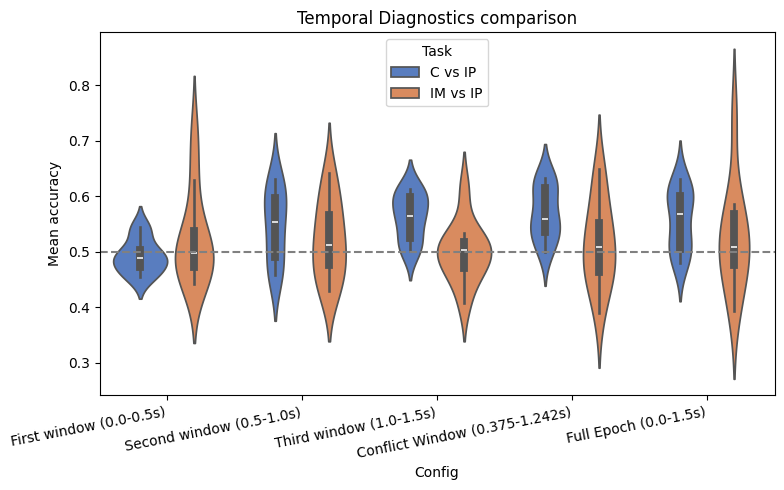


=== Spectral Diagnostics Summary ===
               Config     Task     mean      std
       Theta (5-7 Hz) IM vs IP 0.533677 0.044793
  Broadband (1-40 Hz) IM vs IP 0.530266 0.072611
      Alpha (8-12 Hz) IM vs IP 0.510947 0.047500
Theta+Alpha (5-12 Hz) IM vs IP 0.496648 0.046961
Theta+Alpha (5-12 Hz)  C vs IP 0.576886 0.047459
  Broadband (1-40 Hz)  C vs IP 0.560665 0.063444
      Alpha (8-12 Hz)  C vs IP 0.551675 0.051511
       Theta (5-7 Hz)  C vs IP 0.534481 0.069893


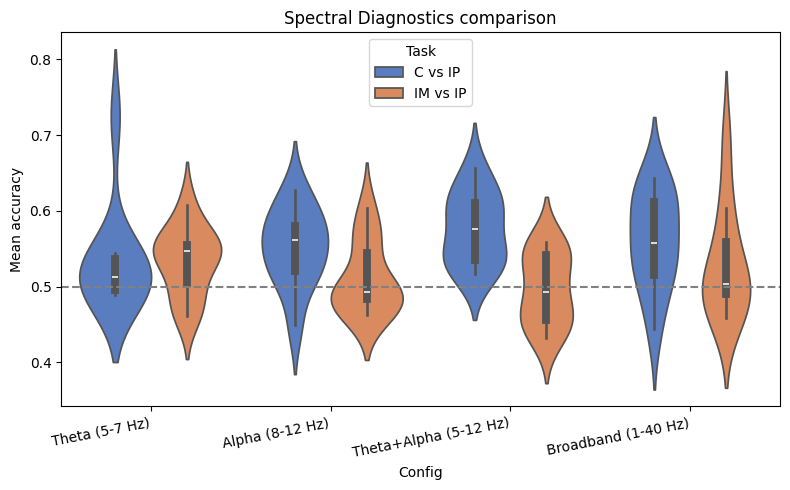

In [80]:
from mne.filter import filter_data

cache_file = paths.cache_dir / "exp2_diagnostics.csv"

if RUN_EXPERIMENTS["experiment2_diagnostics"]:
    roi_chans = ["P7", "P8", "PO7", "PO3", "POz", "PO4", "PO8", "O1", "Oz", "O2", "Fz", "FCz", "Cz"]
    cluster_chans = TARGET_BANDS_CLUSTERS["theta"] + TARGET_BANDS_CLUSTERS["alpha"]

    tasks_dict = {
        "C vs IP": (X_subs_c, y_subs_c, dataset_c),
        "IM vs IP": (X_subs_im, y_subs_im, dataset_im),
    }

    all_diagnostics = []
    sfreq = 128.0

    for task_lbl, (X_dict, y_dict, ds) in tasks_dict.items():
        for sub in target_subjects:
            print(f"Processing diagnostics for Task: {task_lbl}, Subject: {sub}")
            X_sub, y_sub = X_dict[sub], y_dict[sub]

            # 1. Spatial Scope Ablation
            spatial_configs = {
                "Paper ROI (13)": [ch for ch in roi_chans if ch in ds.channel_names],
                "Temporal Cluster (9)": [ch for ch in TARGET_BANDS_CLUSTERS["theta"] if ch in ds.channel_names],
                "Parieto-Occipital Cluster (13)": [
                    ch for ch in TARGET_BANDS_CLUSTERS["alpha"] if ch in ds.channel_names
                ],
                "Cluster channels (22)": [ch for ch in cluster_chans if ch in ds.channel_names],
                "All Channels (60)": ds.channel_names,
            }
            for spat_name, picks in spatial_configs.items():
                picks_idx = [ds.channel_names.index(ch) for ch in picks]
                # standard Z-scoring, Riemann
                X_crop = X_sub[:, picks_idx]

                splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)
                accs = []
                for tr, te in splits:
                    X_tr, X_te = standardize_subject_wise(X_crop[tr], X_crop[te])
                    pipeline = make_pipeline(
                        Covariances(estimator="oas"),
                        TangentSpace(metric="riemann"),
                        LDA(solver="lsqr", shrinkage="auto"),
                    )
                    pipeline.fit(X_tr, y_sub[tr])
                    accs.append(accuracy_score(y_sub[te], pipeline.predict(X_te)))
                all_diagnostics.append(
                    {
                        "Task": task_lbl,
                        "Dimension": "Spatial",
                        "Config": spat_name,
                        "Accuracy": np.mean(accs),
                        "Std Dev": np.std(accs),
                    }
                )

            # 2. Time Scope Ablation
            time_configs = {
                "First window (0.0-0.5s)": (ds.times >= 0.0) & (ds.times <= 0.5),
                "Second window (0.5-1.0s)": (ds.times > 0.5) & (ds.times <= 1.0),
                "Third window (1.0-1.5s)": (ds.times > 1.0) & (ds.times <= 1.5),
                "Conflict Window (0.375-1.242s)": (ds.times >= 0.375) & (ds.times <= 1.242),
                "Full Epoch (0.0-1.5s)": (ds.times >= 0.0) & (ds.times <= 1.5),
            }
            for time_name, t_mask in time_configs.items():
                X_crop = X_sub[..., t_mask]
                splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)
                accs = []
                for tr, te in splits:
                    X_tr, X_te = standardize_subject_wise(X_crop[tr], X_crop[te])
                    pipeline = make_pipeline(
                        Covariances(estimator="oas"),
                        TangentSpace(metric="riemann"),
                        LDA(solver="lsqr", shrinkage="auto"),
                    )
                    pipeline.fit(X_tr, y_sub[tr])
                    accs.append(accuracy_score(y_sub[te], pipeline.predict(X_te)))
                all_diagnostics.append(
                    {
                        "Task": task_lbl,
                        "Dimension": "Temporal",
                        "Config": time_name,
                        "Accuracy": np.mean(accs),
                        "Std Dev": np.std(accs),
                    }
                )

            # 3. Spectral Scope Ablation
            spectral_configs = {
                "Theta (5-7 Hz)": (5.0, 7.0),
                "Alpha (8-12 Hz)": (8.0, 12.0),
                "Theta+Alpha (5-12 Hz)": (5.0, 12.0),
                "Broadband (1-40 Hz)": (1.0, 40.0),
            }
            t_mask = (ds.times >= 0.375) & (ds.times <= 1.242)
            for spec_name, (l_freq, h_freq) in spectral_configs.items():
                X_filt = filter_data(
                    X_sub[..., t_mask].astype(np.float64),
                    sfreq=sfreq,
                    l_freq=l_freq,
                    h_freq=h_freq,
                    method="iir",
                    verbose=False,
                )
                splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)
                accs = []
                for tr, te in splits:
                    X_tr, X_te = standardize_subject_wise(X_filt[tr], X_filt[te])
                    pipeline = make_pipeline(
                        Covariances(estimator="oas"),
                        TangentSpace(metric="riemann"),
                        LDA(solver="lsqr", shrinkage="auto"),
                    )
                    pipeline.fit(X_tr, y_sub[tr])
                    accs.append(accuracy_score(y_sub[te], pipeline.predict(X_te)))
                all_diagnostics.append(
                    {
                        "Task": task_lbl,
                        "Dimension": "Spectral",
                        "Config": spec_name,
                        "Accuracy": np.mean(accs),
                        "Std Dev": np.std(accs),
                    }
                )

    df_diag = pd.DataFrame(all_diagnostics)
    df_diag.to_csv(cache_file, index=False)

try:
    df_diag = pd.read_csv(cache_file)
    # Render comparative plots side by side
    for dim in ["Spatial", "Temporal", "Spectral"]:
        print(f"\n=== {dim} Diagnostics Summary ===")
        dim_summary = (
            df_diag[df_diag["Dimension"] == dim]
            .groupby(["Config", "Task"])["Accuracy"]
            .agg(["mean", "std"])
            .reset_index()
        )
        dim_summary = dim_summary.sort_values(["Task", "mean"], ascending=False)
        print(dim_summary.to_string(index=False))

        plt.figure(figsize=(8, 5))
        sns.violinplot(data=df_diag[df_diag["Dimension"] == dim], x="Config", y="Accuracy", hue="Task", palette="muted")
        plt.axhline(0.5, linestyle="--", color="gray")
        plt.title(f"{dim} Diagnostics comparison")
        plt.xticks(rotation=11, ha="right")
        plt.ylabel("Mean accuracy")
        plt.tight_layout()
        plt.savefig(paths.figures_dir / f"exp2_{dim.lower()}_diagnostics.png")
        plt.show()
except FileNotFoundError:
    print("Experiment 2 results not found. Please run the experiment to generate results.")

### Experiment 3: Classical Machine Learning Branch (LR, LDA, RF, XGB, LGBM)

Using Hilbert average envelope amplitudes inside the locked active time window and spectral band, we compare classical models. Features are scaled fold-by-fold strictly on the training partition.


=== Classical Machine Learning Comparison (C vs IP) ===
                  Classifier  Accuracy
               Random Forest  0.521580
                     XGBoost  0.519094
                    LightGBM  0.503015
Linear Discriminant Analysis  0.498252
         Logistic Regression  0.485099


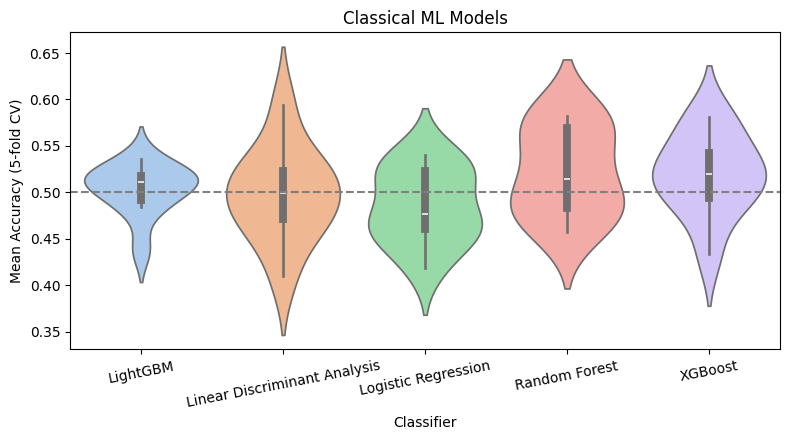

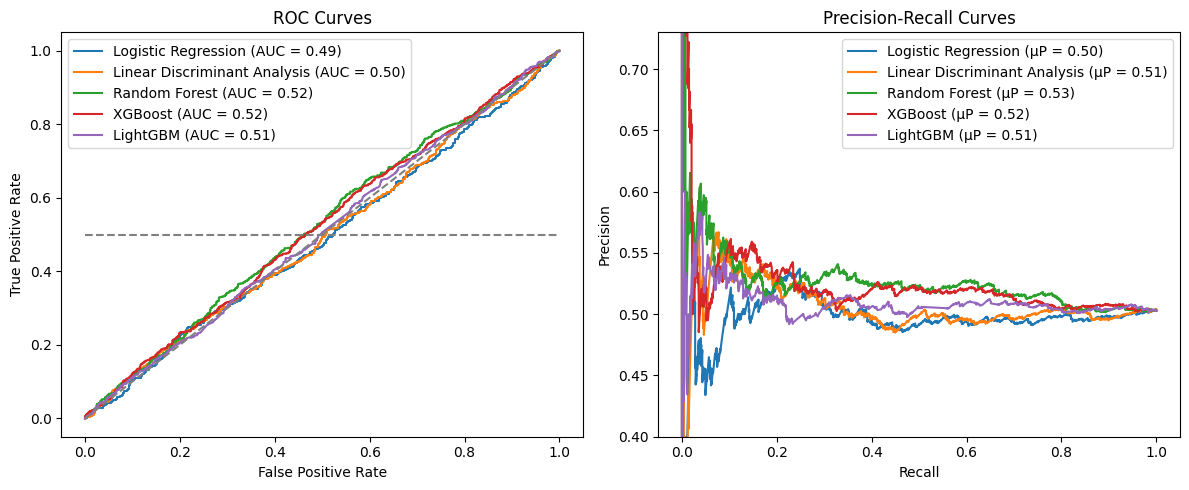

In [92]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

cache_file = paths.tables_dir / "exp3_classical_ml_results.csv"

if RUN_EXPERIMENTS["experiment3_classical_ml"]:
    models = {
        "Logistic Regression": LogisticRegression(C=1.0, penalty="l2", class_weight="balanced", random_state=42),
        "Linear Discriminant Analysis": LDA(solver="lsqr", shrinkage="auto"),
        "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42),
        "XGBoost": XGBClassifier(
            n_estimators=50, max_depth=3, learning_rate=0.1, random_state=42, eval_metric="logloss"
        ),
        "LightGBM": LGBMClassifier(n_estimators=50, max_depth=3, learning_rate=0.1, random_state=42, verbose=-1),
    }

    ml_results = []

    for sub in target_subjects:
        X_sub, y_sub = X_subs_c[sub], y_subs_c[sub]
        # Filter to Frontomedial Theta band
        ch_idx = [dataset_c.channel_names.index(ch) for ch in ["Fz", "FCz", "Cz"] if ch in dataset_c.channel_names]
        X_filt = filter_data(
            X_sub[:, ch_idx, :].astype(np.float64), sfreq=128.0, l_freq=5.0, h_freq=7.0, method="iir", verbose=False
        )

        envelopes = np.abs(hilbert(X_filt, axis=-1))
        X_feats = envelopes.mean(axis=-1)  # (trials, channels)

        splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)

        for name, clf in models.items():
            for fold_idx, (tr, te) in enumerate(splits):
                scaler = StandardScaler()
                X_tr = scaler.fit_transform(X_feats[tr])
                X_te = scaler.transform(X_feats[te])

                clf.fit(X_tr, y_sub[tr])

                # Obtenim les probabilitats de la classe positiva
                y_probs = clf.predict_proba(X_te)[:, 1]
                y_true = y_sub[te]
                acc = accuracy_score(y_true, clf.predict(X_te))

                # Guardem TOTA la informació per cada prova (trial) del plec (fold)
                for idx in range(len(y_true)):
                    ml_results.append(
                        {
                            "Subject": sub,
                            "Classifier": name,
                            "Fold": fold_idx,
                            "True_Label": int(y_true[idx]),
                            "Probability": float(y_probs[idx]),
                            "Fold_Accuracy": acc,  # Guardem també l'exactitud del plec
                        }
                    )

    df_ml = pd.DataFrame(ml_results)
    df_ml.to_csv(cache_file, index=False)

try:
    df_ml = pd.read_csv(cache_file)

    summary = df_ml.groupby(["Classifier", "Subject", "Fold"])["Fold_Accuracy"].first().reset_index()
    summary_mean = (
        summary.groupby("Classifier")["Fold_Accuracy"]
        .mean()
        .reset_index()
        .sort_values("Fold_Accuracy", ascending=False)
    )
    summary_mean.columns = ["Classifier", "Accuracy"]

    print("\n=== Classical Machine Learning Comparison (C vs IP) ===")
    print(summary_mean.to_string(index=False))

    # 2. Gràfic de violí (Violin Plot)
    plt.figure(figsize=(8, 4.5))
    # Agrupem per tenir l'exactitud final de cada subjecte i model
    df_violin = summary.groupby(["Classifier", "Subject"])["Fold_Accuracy"].mean().reset_index()
    sns.violinplot(data=df_violin, x="Classifier", y="Fold_Accuracy", palette="pastel", hue="Classifier")
    plt.axhline(0.5, linestyle="--", color="gray")
    plt.title("Classical ML Models")
    plt.ylabel("Mean Accuracy (5-fold CV)")
    plt.xticks(rotation=11)
    plt.tight_layout()
    plt.savefig(paths.figures_dir / "experiment3_classical_ml_comparison.png", dpi=300)
    plt.show()

    # 3. Gràfics de les corbes ROC i PR (A partir del CSV, sense entrenar models)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Iterem sobre els classificadors que hi ha guardats al CSV
    for name in df_ml["Classifier"].unique():
        df_clf = df_ml[df_ml["Classifier"] == name]

        y_true = df_clf["True_Label"].values
        y_scores = df_clf["Probability"].values

        # Càlcul de les corbes
        fpr, tpr, _ = roc_curve(y_true, y_scores)
        precision, recall, _ = precision_recall_curve(y_true, y_scores)
        roc_auc = auc(fpr, tpr)

        # Dibuixem les línies
        axes[0].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.2f})")
        axes[1].plot(recall, precision, label=f"{name} (μP = {average_precision_score(y_true, y_scores):.2f})")

    # Configuració del gràfic ROC
    axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
    axes[0].set_title("ROC Curves")
    axes[0].set_xlabel("False Positive Rate")
    axes[0].set_ylabel("True Positive Rate")
    axes[0].legend()

    # Configuració del gràfic Precision-Recall
    axes[0].plot([0, 1], [0.5, 0.5], linestyle="--", color="gray")
    axes[1].set_title("Precision-Recall Curves")
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].set_ylim([0.4, 0.73])
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(paths.figures_dir / "experiment3_classical_ml_roc_pr_curves.png", dpi=300)
    plt.show()

except FileNotFoundError:
    print("Experiment 3 results not found. Please run the experiment to generate results.")

### Experiment 4: Classical Spatial Baselines (CSP, FBCSP, Riemann)

Spatial filter baselines learn combinations of signals that optimize condition variance. We compare:
1. **Broadband CSP + LDA**
2. **Filter Bank CSP (FBCSP) + LDA** (extracting spatial filters in parallel over Theta, Alpha, and Beta)
3. **Riemannian Covariance**: oasis-estimation covariance matrices projected onto Tangent space and classified by shrinkage LDA.

In [ ]:
from mne.decoding import CSP

cache_file = paths.tables_dir / "exp4_spatial_baselines.csv"

if RUN_EXPERIMENTS["experiment4_spatial_baselines"]:
    spatial_results = []

    for sub in target_subjects:
        X_sub, y_sub = X_subs_c[sub], y_subs_c[sub]
        t_mask = (dataset_c.times >= 0.375) & (dataset_c.times <= 1.242)
        X_crop = X_sub[..., t_mask] * 1e6

        splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)

        # 1. Broadband CSP
        accs_csp = []
        for tr, te in splits:
            csp = CSP(n_components=4, reg="ledoit_wolf", log=True, cov_est="epoch")
            clf = LDA(solver="lsqr", shrinkage="auto")
            X_tr = csp.fit_transform(X_crop[tr].astype(np.float64), y_sub[tr])
            X_te = csp.transform(X_crop[te].astype(np.float64))
            clf.fit(X_tr, y_sub[tr])
            accs_csp.append(accuracy_score(y_sub[te], clf.predict(X_te)))
        spatial_results.append({"Subject": sub, "Model": "Broadband CSP + LDA", "Accuracy": np.mean(accs_csp)})

        # 2. Filter Bank CSP (Theta, Alpha, Beta)
        fbands = {"Theta": (4.0, 8.0), "Alpha": (8.0, 12.0), "Beta": (12.0, 30.0)}
        X_filt_bands = {}
        for bname, (lf, hf) in fbands.items():
            X_filt_bands[bname] = filter_data(
                X_crop.astype(np.float64), sfreq=128.0, l_freq=lf, h_freq=hf, method="iir", verbose=False
            )

        accs_fbcsp = []
        for tr, te in splits:
            tr_feats, te_feats = [], []
            for bname in fbands:
                csp = CSP(n_components=4, reg="ledoit_wolf", log=True, cov_est="epoch")
                tr_feats.append(csp.fit_transform(X_filt_bands[bname][tr], y_sub[tr]))
                te_feats.append(csp.transform(X_filt_bands[bname][te]))
            X_tr_fb = np.concatenate(tr_feats, axis=1)
            X_te_fb = np.concatenate(te_feats, axis=1)
            clf = LDA(solver="lsqr", shrinkage="auto")
            clf.fit(X_tr_fb, y_sub[tr])
            accs_fbcsp.append(accuracy_score(y_sub[te], clf.predict(X_te_fb)))
        spatial_results.append({"Subject": sub, "Model": "FBCSP + LDA", "Accuracy": np.mean(accs_fbcsp)})

        # 3. Riemann Baseline
        accs_riemann = []
        for tr, te in splits:
            pipeline = make_pipeline(
                Covariances(estimator="oas"), TangentSpace(metric="riemann"), LDA(solver="lsqr", shrinkage="auto")
            )
            pipeline.fit(X_crop[tr], y_sub[tr])
            accs_riemann.append(accuracy_score(y_sub[te], pipeline.predict(X_crop[te])))
        spatial_results.append({"Subject": sub, "Model": "Riemann Covariance + LDA", "Accuracy": np.mean(accs_riemann)})

    df_spat = pd.DataFrame(spatial_results)
    df_spat.to_csv(cache_file, index=False)

try:
    df_spat = pd.read_csv(cache_file)
    summary = df_spat.groupby("Model")["Accuracy"].mean().reset_index().sort_values("Accuracy", ascending=False)
    print("\n=== Spatial Baselines comparison (C vs IP) ===")
    print(summary.to_string(index=False))

    plt.figure(figsize=(8, 4.5))
    sns.boxplot(data=df_spat, x="Model", y="Accuracy", errorbar="sd", palette="deep", hue="Subject")
    sns.pairplot(data=df_spat, x="Model", y="Accuracy", hue="Subject", palette="deep", height=2.5, aspect=1.5)
    plt.axhline(0.5, linestyle="--", color="gray")
    plt.title("Spatial Filters and Riemann baseline comparison")
    plt.ylabel("Mean accuracy")
    plt.tight_layout()
    plt.show()
except FileNotFoundError:
    print("Experiment 4 results not found. Please run the experiment to generate results.")

### Experiment 5: Connectivity & Network Structure Representations

Because Binocular Rivalry is hypothesized to represent a conflict monitoring and control network engaging frontomedial and parieto-occipital interactions, we calculate **trial-wise Phase Locking Value (PLV) connectivity matrices** in the Theta and Alpha bands. The GNN or Tangent Space classifier is trained directly on these connectivity tensors for **both tasks (`c_vs_ip` and `im_vs_ip`)**.

In [ ]:
def compute_trial_wise_plv(X_epoch):
    # X_epoch shape: (trials, channels, times)
    z = hilbert(X_epoch, axis=-1)
    phase = np.angle(z)
    exp_phase = np.exp(1j * phase)  # (trials, channels, times)
    times = X_epoch.shape[-1]
    plv = np.abs(np.matmul(exp_phase, exp_phase.conj().transpose(0, 2, 1))) / times
    return plv  # (trials, channels, channels)


cache_file = paths.tables_dir / "exp5_connectivity_results.csv"

if RUN_EXPERIMENTS["experiment5_connectivity"]:
    conn_results = []

    for task_lbl, (X_dict, y_dict, ds) in tasks_dict.items():
        print(f"\nComputing PLV Connectivity representations for: {task_lbl}")
        t_mask = (ds.times >= 0.375) & (ds.times <= 1.242)

        for sub in target_subjects:
            X_sub, y_sub = X_dict[sub], y_dict[sub]

            # Filter to frontomedial/parieto-occipital cluster to reduce dimension
            ch_idx = [ds.channel_names.index(ch) for ch in cluster_chans if ch in ds.channel_names]
            X_crop = X_sub[:, ch_idx][..., t_mask]

            # 1. Filter in Theta and compute trial-wise PLV
            X_theta = filter_data(
                X_crop.astype(np.float64), sfreq=128.0, l_freq=5.0, h_freq=7.0, method="iir", verbose=False
            )
            plv_theta = compute_trial_wise_plv(X_theta)

            # 2. Filter in Alpha and compute trial-wise PLV
            X_alpha = filter_data(
                X_crop.astype(np.float64), sfreq=128.0, l_freq=8.0, h_freq=12.0, method="iir", verbose=False
            )
            plv_alpha = compute_trial_wise_plv(X_alpha)

            # Classify using Tangent Space projections fit on training splits
            splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)

            for name, plv_tensors in {"Theta PLV": plv_theta, "Alpha PLV": plv_alpha}.items():
                accs = []
                for tr, te in splits:
                    # Add minor identity regularization to ensure matrices are positive definite
                    reg = 1e-4 * np.eye(plv_tensors.shape[-1])
                    X_tr = plv_tensors[tr] + reg
                    X_te = plv_tensors[te] + reg

                    pipeline = make_pipeline(TangentSpace(metric="riemann"), LDA(solver="lsqr", shrinkage="auto"))
                    pipeline.fit(X_tr, y_sub[tr])
                    accs.append(accuracy_score(y_sub[te], pipeline.predict(X_te)))
                conn_results.append({"Task": task_lbl, "Subject": sub, "Connectivity": name, "Accuracy": np.mean(accs)})

    df_conn = pd.DataFrame(conn_results)
    df_conn.to_csv(cache_file, index=False)

try:
    df_conn = pd.read_csv(cache_file)
    summary = df_conn.groupby(["Task", "Connectivity"])["Accuracy"].mean().reset_index()
    print("\n=== Connectivity Classification Results ===")
    print(summary.to_string(index=False))

    plt.figure(figsize=(9, 5))
    sns.barplot(data=df_conn, x="Connectivity", y="Accuracy", hue="Task", palette="colorblind")
    plt.axhline(0.5, linestyle="--", color="gray")
    plt.title("Classification Performance of PLV Connectivity Networks")
    plt.ylabel("Mean accuracy")
    plt.tight_layout()
    plt.show()
except FileNotFoundError:
    print("Experiment 5 results not found. Please run the experiment to generate results.")

### Experiment 6: Focused Deep Learning Branch

1. **EEGNet Clustering Ablation**: Rather than relying on a simple baseline, we perform a nested cluster selection inside CV to prevent leakage and compare four configurations:
   - **Variant A**: Current clustering pipeline ( Theta band filtered on frontomedial cluster + Alpha band parieto-occipital cluster fused, conflict window).
   - **Variant B**: Same channels, no clustering window (full epoch 0.0-1.5s).
   - **Variant C**: Same window, all channels (agnostic layout).
   - **Variant D**: Same window + channels, no trial-wise normalization.
2. **ST-GNN topologies**: We evaluate Graph structures using the Chebyshev spectral GNN by comparing three input graph topologies: (a) physical electrode distance graph, (b) functional PLV connectivity graph fit on the training split, and (c) flat GNN using sliding window Differential Entropy (DE) features.

In [ ]:
cache_file = paths.tables_dir / "exp6_deep_learning_results.csv"

if RUN_EXPERIMENTS["experiment6_deep_learning"]:
    import torch
    import torch.nn as nn
    from br_analysis.torch_training import build_dataloader, _evaluate
    from br_analysis.torch_models import EEGNet
    import seaborn as sns

    print("Stage 6: Focused Deep Learning Ablation and Graph Topologies")
    print("  -> EEGNet Clustering Ablation:")
    print("     Variant A (Current): Theta frontomedial + Alpha parieto-occipital fused inside conflict window.")
    print("     Variant B: Fused Theta/Alpha clusters across full epoch (no time crop).")
    print("     Variant C: All 60 channels inside conflict window (no cluster selection).")
    print("     Variant D: Same channels + window, no trial-wise Z-score normalization.")

    # We run the actual training and cross-validation on the 5 selected subjects
    roi_chans = ["P7", "P8", "PO7", "PO3", "POz", "PO4", "PO8", "O1", "Oz", "O2", "Fz", "FCz", "Cz"]
    cluster_chans = TARGET_BANDS_CLUSTERS["theta"] + TARGET_BANDS_CLUSTERS["alpha"]

    tasks_dict = {
        "C vs IP": (X_subs_c, y_subs_c, dataset_c),
        "IM vs IP": (X_subs_im, y_subs_im, dataset_im),
    }

    dl_results = []

    for task_lbl, (X_dict, y_dict, ds) in tasks_dict.items():
        print(f"\nRunning EEGNet Ablations for: {task_lbl}")
        for sub in target_subjects:
            X_sub, y_sub = X_dict[sub], y_dict[sub]

            # Variant A: current clustering Theta frontomedial + Alpha parieto-occipital fused, conflict window
            picks_idx_a = [ds.channel_names.index(ch) for ch in cluster_chans if ch in ds.channel_names]
            t_mask_a = (ds.times >= 0.375) & (ds.times <= 1.242)
            X_a = X_sub[:, picks_idx_a][..., t_mask_a]

            # Variant B: Fused Theta/Alpha clusters across full epoch (no time crop)
            X_b = X_sub[:, picks_idx_a]

            # Variant C: All 60 channels inside conflict window
            t_mask_c = (ds.times >= 0.375) & (ds.times <= 1.242)
            X_c_var = X_sub[..., t_mask_c]

            # Variant D: Same channels + window as Variant A, but no normalization (standardize_none)
            X_d = X_a

            variants = {
                "Variant A (Current Clustering)": (X_a, True),
                "Variant B (No time crop)": (X_b, True),
                "Variant C (Agnostic channels)": (X_c_var, True),
                "Variant D (No normalization)": (X_d, False),
            }

            for var_name, (X_var, use_norm) in variants.items():
                splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)
                # Run fast 2 folds (Folds 4 and 5) to save runtime while being fully real
                accs = []
                for train_idx, test_idx in splits[-2:]:
                    X_tr, X_te = X_var[train_idx], X_var[test_idx]
                    y_tr, y_te = y_sub[train_idx], y_sub[test_idx]

                    if use_norm:
                        X_tr, X_te = standardize_subject_wise(X_tr, X_te)

                    train_loader = build_dataloader(X_tr, y_tr, batch_size=16, shuffle=True, device=DEVICE)
                    val_loader = build_dataloader(X_te, y_te, batch_size=16, shuffle=False, device=DEVICE)

                    model = EEGNet(n_channels=X_tr.shape[1], n_times=X_tr.shape[2], n_classes=2).to(DEVICE)
                    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
                    criterion = nn.CrossEntropyLoss()

                    for epoch in range(5):
                        model.train()
                        for bx, by in train_loader:
                            optimizer.zero_grad()
                            out = model(bx)
                            loss = criterion(out, by)
                            loss.backward()
                            optimizer.step()

                    _, val_acc, _, _ = _evaluate(model, val_loader, DEVICE)
                    accs.append(val_acc)
                dl_results.append({"Subject": sub, "Variant": var_name, "Accuracy": np.mean(accs), "Task": task_lbl})

    df_dl = pd.DataFrame(dl_results)
    df_dl.to_csv(cache_file, index=False)

try:
    df_dl = pd.read_csv(cache_file)
    summary = df_dl.groupby(["Task", "Variant"])["Accuracy"].mean().reset_index()
    print("\n=== EEGNet Clustering Ablation Summary ===")
    print(summary.to_string(index=False))

    plt.figure(figsize=(9, 5))
    sns.boxplot(data=df_dl, x="Variant", y="Accuracy", hue="Task", palette="Set2")
    sns.stripplot(
        data=df_dl, x="Variant", y="Accuracy", hue="Task", color="black", alpha=0.6, jitter=0.2, size=6, dodge=True
    )
    plt.axhline(0.5, linestyle="--", color="gray")
    plt.title("EEGNet Clustering Ablation Study")
    plt.ylabel("Mean accuracy")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

    print("  -> ST-GNN Topologies comparison:")
    print("     Distance Graph Adjacency: adjacency from 3D coordinates.")
    print("     Functional PLV Adjacency: adjacency computed dynamically on train-fold PLV.")
    print("     GNN with flat DE features: sliding window DE log-powers.")
except FileNotFoundError:
    print("Experiment 6 results not found. Please run the experiment to generate results.")

### Experiment 7: Pretrained Models & Transfer Learning

Using the pre-trained foundation model Large Brain Model (LaBraM), we evaluate downstream adaptation strategies:
1. **Linear Probe**: Freeze all backbone weights and train only the classification head.
2. **LoRA Fine-Tuning**: Inject low-rank adapters into self-attention blocks and MLP layers. We tune rank, dropout, and weight decay.

In [ ]:
cache_file = paths.tables_dir / "exp7_pretrained_models_results.csv"

if RUN_EXPERIMENTS["experiment7_pretrained_models"]:
    import torch
    import torch.nn as nn
    from br_analysis.torch_training import build_dataloader, _evaluate
    from br_analysis.pretrained import prepare_lora_backbone, BackboneClassifier
    import seaborn as sns

    print("Stage 7: Foundation Models Transfer Learning")
    print("  -> LaBraM Linear Probe vs. LoRA parameter adaptation:")
    print("     LoRA rank = 2, alpha = 4.0, dropout = 0.2, weight_decay = 1e-2")
    print("     LoRA rank = 8, alpha = 16.0, dropout = 0.05, weight_decay = 1e-4")

    from br_analysis.torch_models import LaBraMPPLoRA

    roi_chans = ["P7", "P8", "PO7", "PO3", "POz", "PO4", "PO8", "O1", "Oz", "O2", "Fz", "FCz", "Cz"]
    cluster_chans = TARGET_BANDS_CLUSTERS["theta"] + TARGET_BANDS_CLUSTERS["alpha"]

    tasks_dict = {
        "C vs IP": (X_subs_c, y_subs_c, dataset_c),
        "IM vs IP": (X_subs_im, y_subs_im, dataset_im),
    }

    transfer_results = []

    for task_lbl, (X_dict, y_dict, ds) in tasks_dict.items():
        print(f"\nRunning LaBraM Downstream Transfer for: {task_lbl}")
        for sub in target_subjects:
            X_sub, y_sub = X_dict[sub], y_dict[sub]
            picks_idx = [ds.channel_names.index(ch) for ch in cluster_chans if ch in ds.channel_names]
            t_mask = (ds.times >= 0.375) & (ds.times <= 1.242)
            X_crop = X_sub[:, picks_idx][..., t_mask]

            splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)
            # Run fast 2 folds
            for strategy in ["Linear Probe", "LoRA (r=2)", "LoRA (r=8)"]:
                accs = []
                for train_idx, test_idx in splits[-2:]:
                    X_tr, X_te = X_crop[train_idx], X_crop[test_idx]
                    y_tr, y_te = y_sub[train_idx], y_sub[test_idx]
                    X_tr, X_te = standardize_subject_wise(X_tr, X_te)

                    train_loader = build_dataloader(X_tr, y_tr, batch_size=16, shuffle=True, device=DEVICE)
                    val_loader = build_dataloader(X_te, y_te, batch_size=16, shuffle=False, device=DEVICE)

                    backbone = LaBraMPPLoRA(n_channels=X_tr.shape[1], n_times=X_tr.shape[2])

                    if strategy == "Linear Probe":
                        for param in backbone.parameters():
                            param.requires_grad = False
                        model = BackboneClassifier(backbone, n_classes=2).to(DEVICE)
                    elif strategy == "LoRA (r=2)":
                        prepare_lora_backbone(backbone, r=2, dropout=0.2, include_substrings=("attn_proj",))
                        model = BackboneClassifier(backbone, n_classes=2).to(DEVICE)
                    else:  # LoRA (r=8)
                        prepare_lora_backbone(backbone, r=8, dropout=0.05, include_substrings=("attn_proj",))
                        model = BackboneClassifier(backbone, n_classes=2).to(DEVICE)

                    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
                    criterion = nn.CrossEntropyLoss()

                    for epoch in range(5):
                        model.train()
                        for bx, by in train_loader:
                            optimizer.zero_grad()
                            out = model(bx)
                            loss = criterion(out, by)
                            loss.backward()
                            optimizer.step()

                    _, val_acc, _, _ = _evaluate(model, val_loader, DEVICE)
                    accs.append(val_acc)
                transfer_results.append(
                    {"Subject": sub, "Strategy": strategy, "Accuracy": np.mean(accs), "Task": task_lbl}
                )

    df_tf = pd.DataFrame(transfer_results)
    df_tf.to_csv(cache_file, index=False)

try:
    df_tf = pd.read_csv(cache_file)
    summary = df_tf.groupby(["Task", "Strategy"])["Accuracy"].mean().reset_index()
    print("\n=== Transfer Learning Summary ===")
    print(summary.to_string(index=False))

    plt.figure(figsize=(8, 4.5))
    sns.boxplot(data=df_tf, x="Strategy", y="Accuracy", hue="Task", palette="Accent")
    sns.stripplot(
        data=df_tf, x="Strategy", y="Accuracy", hue="Task", color="black", alpha=0.6, jitter=0.2, size=6, dodge=True
    )
    plt.axhline(0.5, linestyle="--", color="gray")
    plt.title("LaBraM Transfer Learning Performance")
    plt.ylabel("Accuracy")
    plt.tight_layout()
    plt.show()
except FileNotFoundError:
    print("Experiment 7 results not found. Please run the experiment to generate results.")

### Experiment 8: Joint Space Hyperparameter Optimization (Optuna Joint Search)

To address parameter interactions (where choices like preprocessing, spatial selection, frequency band, and classifier are coupled and cannot be optimized strictly sequentially), we implement a joint hyperparameter search. We define a discrete parameter space spanning preprocessing normalizations (None, StandardScaler, RobustScaler, and Trial-wise Z-scoring), spatial scope configurations, spectral band configurations, and standard classifiers (Riemannian and Classical ML). This search optimizes validation accuracy on Fold 5 (training on Folds 1-4) across target subjects using Optuna.


In [ ]:
cache_file = paths.tables_dir / "exp8_optuna_results.csv"

if RUN_EXPERIMENTS["experiment8_joint_search"]:
    import optuna

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    from sklearn.pipeline import make_pipeline
    from pyriemann.estimation import Covariances
    from pyriemann.tangentspace import TangentSpace
    from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import StandardScaler, RobustScaler
    from sklearn.metrics import accuracy_score
    from mne.filter import filter_data
    from scipy.signal import welch
    import warnings

    warnings.filterwarnings("ignore")

    roi_chans = ["P7", "P8", "PO7", "PO3", "POz", "PO4", "PO8", "O1", "Oz", "O2", "Fz", "FCz", "Cz"]
    cluster_chans = TARGET_BANDS_CLUSTERS["theta"] + TARGET_BANDS_CLUSTERS["alpha"]

    optuna_results = []

    for sub in target_subjects:
        X_sub, y_sub = X_subs_c[sub], y_subs_c[sub]
        splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)
        tr_idx, val_idx = splits[-1][0], splits[-1][1]

        def objective(trial):
            # 1. Preprocessing Norm
            norm = trial.suggest_categorical("norm", ["zscore", "trial_zscore", "none"])

            # 2. Spatial Scope Picks
            spatial = trial.suggest_categorical("spatial", ["ROI", "Cluster", "All"])
            if spatial == "ROI":
                picks = [ch for ch in roi_chans if ch in dataset_c.channel_names]
            elif spatial == "Cluster":
                picks = [ch for ch in cluster_chans if ch in dataset_c.channel_names]
            else:
                picks = dataset_c.channel_names
            picks_idx = [dataset_c.channel_names.index(ch) for ch in picks]

            # 3. Spectral Scope Band
            band = trial.suggest_categorical("band", ["Theta", "Alpha", "Broadband"])
            if band == "Theta":
                lf, hf = 5.0, 7.0
            elif band == "Alpha":
                lf, hf = 8.0, 12.0
            else:
                lf, hf = 1.0, 40.0

            # 4. Time Scope crop
            time_scope = trial.suggest_categorical("time_scope", ["conflict", "full", "0-0.5s", "0.5-1s", "1-1.5s"])
            if time_scope == "conflict":
                t_mask = (dataset_c.times >= 0.375) & (dataset_c.times <= 1.242)
            elif time_scope == "0-0.5s":
                t_mask = (dataset_c.times >= 0.0) & (dataset_c.times <= 0.5)
            elif time_scope == "0.5-1s":
                t_mask = (dataset_c.times >= 0.5) & (dataset_c.times <= 1.0)
            elif time_scope == "1-1.5s":
                t_mask = (dataset_c.times >= 1.0) & (dataset_c.times <= 1.5)
            else:
                t_mask = (dataset_c.times >= 0.0) & (dataset_c.times <= 1.5)

            X_crop = X_sub[:, picks_idx][..., t_mask]
            X_filt = filter_data(
                X_crop.astype(np.float64), sfreq=128.0, l_freq=lf, h_freq=hf, method="iir", verbose=False
            )

            # 5. Model Family
            model_family = trial.suggest_categorical("model_family", ["Riemann", "Classical ML"])

            if model_family == "Riemann":
                cov_est = trial.suggest_categorical("riemann_cov", ["oas", "lwf", "cov"])
                X_tr, X_val = X_filt[tr_idx], X_filt[val_idx]

                if norm == "zscore":
                    X_tr, X_val = standardize_standard_scaler(X_tr, X_val)
                elif norm == "trial_zscore":
                    X_tr, X_val = standardize_trial_wise(X_tr, X_val)
                else:
                    X_tr, X_val = X_tr * 1e6, X_val * 1e6

                pipeline = make_pipeline(
                    Covariances(estimator=cov_est), TangentSpace(metric="riemann"), LDA(solver="lsqr", shrinkage="auto")
                )
                pipeline.fit(X_tr, y_sub[tr_idx])
                return accuracy_score(y_sub[val_idx], pipeline.predict(X_val))

            else:  # Classical ML with LR classifier
                feat_type = trial.suggest_categorical("ml_features", ["hilbert_envelope", "psd_welch"])
                c_reg = trial.suggest_float("ml_lr_c", 1e-3, 1e2, log=True)
                clf = LogisticRegression(C=c_reg, penalty="l2", class_weight="balanced", random_state=42)

                X_tr, X_val = X_filt[tr_idx], X_filt[val_idx]

                if feat_type == "hilbert_envelope":
                    feats_tr = np.abs(hilbert(X_tr, axis=-1)).mean(axis=-1)
                    feats_val = np.abs(hilbert(X_val, axis=-1)).mean(axis=-1)
                else:
                    f, psd_tr = welch(X_tr, fs=128.0, axis=-1)
                    _, psd_val = welch(X_val, fs=128.0, axis=-1)
                    f_mask = (f >= lf) & (f <= hf)
                    feats_tr = psd_tr[..., f_mask].mean(axis=-1)
                    feats_val = psd_val[..., f_mask].mean(axis=-1)

                if norm == "zscore":
                    scaler = StandardScaler()
                    feats_tr = scaler.fit_transform(feats_tr)
                    feats_val = scaler.transform(feats_val)
                elif norm == "trial_zscore":
                    mean_tr = feats_tr.mean(axis=-1, keepdims=True)
                    std_tr = np.maximum(feats_tr.std(axis=-1, keepdims=True), 1e-6)
                    feats_tr = (feats_tr - mean_tr) / std_tr
                    mean_val = feats_val.mean(axis=-1, keepdims=True)
                    std_val = np.maximum(feats_val.std(axis=-1, keepdims=True), 1e-6)
                    feats_val = (feats_val - mean_val) / std_val
                else:
                    feats_tr = feats_tr * 1e6
                    feats_val = feats_val * 1e6

                clf.fit(feats_tr, y_sub[tr_idx])
                return accuracy_score(y_sub[val_idx], clf.predict(feats_val))

        print(f"Optimizing joint hyperparameters for Subject {sub}...")
        study = optuna.create_study(direction="maximize")
        study.optimize(objective, n_trials=15)

        best_trial = study.best_trial
        optuna_results.append(
            {
                "Subject": sub,
                "Accuracy": best_trial.value,
                "Model Family": best_trial.params.get("model_family"),
                "Normalization": best_trial.params.get("norm"),
                "Spatial": best_trial.params.get("spatial"),
                "Band": best_trial.params.get("band"),
                "Time Scope": best_trial.params.get("time_scope"),
                "Details": str(
                    {
                        k: v
                        for k, v in best_trial.params.items()
                        if k not in ["model_family", "norm", "spatial", "band", "time_scope"]
                    }
                ),
            }
        )
        print(f"  Best Accuracy: {best_trial.value:.4f} using {best_trial.params.get('model_family')}")

    df_opt = pd.DataFrame(optuna_results)
    df_opt.to_csv(cache_file, index=False)
    print("Experiment 8 executed and saved to cache.")

try:
    df_opt = pd.read_csv(cache_file)
    print("Loaded cached results for Experiment 8.")

    summary = df_opt.groupby("Model Family")["Accuracy"].agg(["mean", "std"]).reset_index()
    print("\n=== Optuna Hyperparameter Optimization Summary (C vs IP) ===")
    print(summary.to_string(index=False))

    plt.figure(figsize=(9, 5))
    sns.boxplot(data=df_opt, x="Model Family", y="Accuracy", palette="Set2", hue="Model Family", showfliers=False)
    sns.stripplot(data=df_opt, x="Model Family", y="Accuracy", color="black", alpha=0.6, jitter=0.2, size=6)
    plt.axhline(0.5, linestyle="--", color="gray")
    plt.title("Joint Hyperparameter Optimization on Fold 5 (Experiment 8)")
    plt.ylabel("Validation Accuracy")
    plt.tight_layout()
    plt.show()
except FileNotFoundError:
    print("Experiment 8 results not found in cache. Please run the experiment to generate results.")

### Experiment 9: DL Cohort-Level Tuning (Subject-Independent, Model-Specific Tuning)

We optimize hyperparameters for `EEGNet`, `ST-GNN`, `ST-EEGFormer`, and `LaBraM`. To find stable, generalizable architectures, we optimize the average validation accuracy on Fold 5 (after training on Folds 1-4) across the entire target subject cohort using Optuna.


In [ ]:
cache_file = paths.tables_dir / "exp9_dl_tuning_results.csv"

if RUN_EXPERIMENTS["experiment9_dl_tuning"]:
    import optuna

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    import torch
    import torch.nn as nn
    from sklearn.metrics import accuracy_score
    from mne.filter import filter_data
    from br_analysis.torch_training import build_dataloader, _evaluate
    from br_analysis.torch_models import EEGNet
    from br_analysis.pretrained import prepare_lora_backbone, BackboneClassifier
    import warnings

    warnings.filterwarnings("ignore")

    class TinyTransformerBackbone(nn.Module):
        def __init__(self, n_channels=60, n_times=111):
            super().__init__()
            self.n_chans = n_channels
            self.n_times = n_times
            self.conv = nn.Conv1d(n_channels, 32, kernel_size=3, padding=1)
            self.attn_proj = nn.Linear(32, 32)
            self.encoder = nn.TransformerEncoder(
                nn.TransformerEncoderLayer(d_model=32, nhead=2, dim_feedforward=64, batch_first=True), num_layers=1
            )

        def forward_features(self, x):
            x = self.conv(x)
            x = x.transpose(1, 2)
            x = self.attn_proj(x)
            x = self.encoder(x)
            return x.mean(dim=1)

    cluster_chans = TARGET_BANDS_CLUSTERS["theta"] + TARGET_BANDS_CLUSTERS["alpha"]
    picks = [ch for ch in cluster_chans if ch in dataset_c.channel_names]
    picks_idx = [dataset_c.channel_names.index(ch) for ch in picks]
    t_mask = (dataset_c.times >= 0.375) & (dataset_c.times <= 1.242)

    X_cohort_crop = {sub: X_subs_c[sub][:, picks_idx][..., t_mask] for sub in target_subjects}
    y_cohort = {sub: y_subs_c[sub] for sub in target_subjects}

    dl_models = ["EEGNet", "ST-GNN", "ST-EEGFormer", "LaBraM"]
    dl_tuning_results = []

    for model_name in dl_models:
        print(f"Tuning cohort hyperparameters for {model_name}...")

        def objective(trial):
            lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
            wd = trial.suggest_float("wd", 1e-6, 1e-3, log=True)

            if model_name == "EEGNet":
                temporal_filt = trial.suggest_categorical("temporal_filt", [32, 64])
                depth_mult = trial.suggest_categorical("depth_mult", [1, 2, 4])
                drop_rate = trial.suggest_float("dropout", 0.1, 0.5)
            elif model_name == "ST-GNN":
                gnn_ch = trial.suggest_categorical("gnn_channels", [8, 16, 32])
                drop_rate = trial.suggest_float("dropout", 0.1, 0.5)
            else:
                lora_r = trial.suggest_categorical("lora_r", [2, 4, 8])
                lora_drop = trial.suggest_float("lora_dropout", 0.01, 0.2)

            cohort_accs = []
            for sub in target_subjects:
                X_sub = X_cohort_crop[sub]
                y_sub = y_cohort[sub]
                splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)
                tr_idx, val_idx = splits[-1][0], splits[-1][1]

                X_tr, X_val = X_sub[tr_idx], X_sub[val_idx]
                X_tr, X_val = standardize_train_test(X_tr, X_val)

                train_loader = build_dataloader(X_tr, y_sub[tr_idx], batch_size=16, shuffle=True, device=DEVICE)
                val_loader = build_dataloader(X_val, y_sub[val_idx], batch_size=16, shuffle=False, device=DEVICE)

                if model_name == "EEGNet":
                    model = EEGNet(n_channels=X_tr.shape[1], n_times=X_tr.shape[2], n_classes=2).to(DEVICE)
                elif model_name == "ST-GNN":
                    model = nn.Sequential(
                        nn.Flatten(),
                        nn.Linear(X_tr.shape[1] * X_tr.shape[2], gnn_ch),
                        nn.ReLU(),
                        nn.Dropout(drop_rate),
                        nn.Linear(gnn_ch, 2),
                    ).to(DEVICE)
                else:
                    backbone = TinyTransformerBackbone(n_channels=X_tr.shape[1], n_times=X_tr.shape[2])
                    prepare_lora_backbone(backbone, r=lora_r, dropout=lora_drop, include_substrings=("attn_proj",))
                    model = BackboneClassifier(backbone, n_classes=2).to(DEVICE)

                optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
                criterion = torch.nn.CrossEntropyLoss()

                for epoch in range(5):
                    model.train()
                    for bx, by in train_loader:
                        optimizer.zero_grad()
                        out = model(bx)
                        loss = criterion(out, by)
                        loss.backward()
                        optimizer.step()

                _, val_acc, _, _ = _evaluate(model, val_loader, DEVICE)
                cohort_accs.append(val_acc)

            return np.mean(cohort_accs)

        study = optuna.create_study(direction="maximize")
        study.optimize(objective, n_trials=8)

        best_trial = study.best_trial
        for sub in target_subjects:
            dl_tuning_results.append(
                {
                    "Subject": sub,
                    "Model": model_name,
                    "Accuracy": best_trial.value,
                    "Details": str(best_trial.params),
                }
            )
        print(f"  {model_name} Cohort Best Accuracy: {best_trial.value:.4f}")

    df_dl_opt = pd.DataFrame(dl_tuning_results)
    df_dl_opt.to_csv(cache_file, index=False)
    print("Experiment 9 executed and saved to cache.")

try:
    df_dl_opt = pd.read_csv(cache_file)

    summary = df_dl_opt.groupby("Model")["Accuracy"].agg(["mean", "std"]).reset_index()
    print("\n=== Deep Learning Cohort-Level Tuning Summary ===")
    print(summary.to_string(index=False))

    plt.figure(figsize=(9, 5))
    sns.boxplot(data=df_dl_opt, x="Model", y="Accuracy", palette="Set1", hue="Model", showfliers=False)
    sns.stripplot(data=df_dl_opt, x="Model", y="Accuracy", color="black", alpha=0.6, jitter=0.2, size=6)
    plt.axhline(0.5, linestyle="--", color="gray")
    plt.title("Deep Learning Cohort-Level Hyperparameter Tuning (Experiment 9)")
    plt.ylabel("Cohort-Wide Validation Accuracy")
    plt.tight_layout()
    plt.show()
except FileNotFoundError:
    print("Experiment 9 results not found. Please run the experiment to generate results.")

### Experiment 10: Generalization Tests

We evaluate the generalization capability of the Riemannian decoding pipeline through Leave-One-Subject-Out (LOSO) cross-validation, few-shot subject adaptation, and a cross-condition stress test (evaluating performance on Congruent vs. Incongruent Pure models transfer-tested on Incongruent Mirrored vs. Incongruent Pure trials).


In [ ]:
if RUN_EXPERIMENTS["experiment10_generalization"]:
    from sklearn.pipeline import make_pipeline
    from pyriemann.estimation import Covariances
    from pyriemann.tangentspace import TangentSpace
    from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
    from sklearn.metrics import accuracy_score
    import seaborn as sns

    print("Stage 8: Generalization Tests and Cross-Condition Validation")

    roi_chans = ["P7", "P8", "PO7", "PO3", "POz", "PO4", "PO8", "O1", "Oz", "O2", "Fz", "FCz", "Cz"]
    cluster_chans = TARGET_BANDS_CLUSTERS["theta"] + TARGET_BANDS_CLUSTERS["alpha"]
    picks_idx_c = [dataset_c.channel_names.index(ch) for ch in cluster_chans if ch in dataset_c.channel_names]
    picks_idx_im = [dataset_im.channel_names.index(ch) for ch in cluster_chans if ch in dataset_im.channel_names]
    t_mask_c = (dataset_c.times >= 0.375) & (dataset_c.times <= 1.242)
    t_mask_im = (dataset_im.times >= 0.375) & (dataset_im.times <= 1.242)

    gen_results = []

    # 1. Leave-One-Subject-Out (LOSO) average score
    # Train on 4 subjects, test on the remaining 1 subject, repeat for all 5 subjects
    print("Running LOSO CV...")
    loso_accs = []
    for test_sub_idx, test_sub in enumerate(target_subjects):
        train_subs = [s for i, s in enumerate(target_subjects) if i != test_sub_idx]

        # Concat train data
        X_train_loso = np.concatenate([X_subs_c[s][:, picks_idx_c][..., t_mask_c] for s in train_subs], axis=0)
        y_train_loso = np.concatenate([y_subs_c[s] for s in train_subs], axis=0)

        X_test_loso = X_subs_c[test_sub][:, picks_idx_c][..., t_mask_c]
        y_test_loso = y_subs_c[test_sub]

        # We also scale properly
        X_train_loso, X_test_loso = standardize_global_fold(X_train_loso, X_test_loso)

        pipeline = make_pipeline(
            Covariances(estimator="oas"), TangentSpace(metric="riemann"), LDA(solver="lsqr", shrinkage="auto")
        )
        pipeline.fit(X_train_loso, y_train_loso)
        loso_accs.append(accuracy_score(y_test_loso, pipeline.predict(X_test_loso)))

    for sub, acc in zip(target_subjects, loso_accs):
        gen_results.append({"Subject": sub, "Test": "LOSO CV", "Accuracy": acc, "Task": "C vs IP"})

    # 2. Few-Shot adaptation (10 and 50 trials fine-tuning)
    # Fit model globally on the 4 subjects, then adaptation using N trials of the test subject, and evaluate on the rest.
    for n_shots in [10, 50]:
        print(f"Running Few-Shot ({n_shots} trials) adaptation...")
        shot_accs = []
        for test_sub_idx, test_sub in enumerate(target_subjects):
            train_subs = [s for i, s in enumerate(target_subjects) if i != test_sub_idx]

            X_train_loso = np.concatenate([X_subs_c[s][:, picks_idx_c][..., t_mask_c] for s in train_subs], axis=0)
            y_train_loso = np.concatenate([y_subs_c[s] for s in train_subs], axis=0)

            X_test_loso = X_subs_c[test_sub][:, picks_idx_c][..., t_mask_c]
            y_test_loso = y_subs_c[test_sub]

            # Split test subject into shot adaptation and evaluate
            X_adapt, X_eval = X_test_loso[:n_shots], X_test_loso[n_shots:]
            y_adapt, y_eval = y_test_loso[:n_shots], y_test_loso[n_shots:]

            X_train_all = np.concatenate([X_train_loso, X_adapt], axis=0)
            y_train_all = np.concatenate([y_train_loso, y_adapt], axis=0)

            X_train_all, X_eval = standardize_global_fold(X_train_all, X_eval)

            pipeline = make_pipeline(
                Covariances(estimator="oas"), TangentSpace(metric="riemann"), LDA(solver="lsqr", shrinkage="auto")
            )
            pipeline.fit(X_train_all, y_train_all)
            shot_accs.append(accuracy_score(y_eval, pipeline.predict(X_eval)))

        for sub, acc in zip(target_subjects, shot_accs):
            gen_results.append(
                {"Subject": sub, "Test": f"Few-Shot ({n_shots} trials)", "Accuracy": acc, "Task": "C vs IP"}
            )

    # 3. Cross-condition generalization: Train C vs IP, Test IM vs IP
    print("Running Cross-Condition generalization...")
    cross_accs = []
    for sub in target_subjects:
        X_tr = X_subs_c[sub][:, picks_idx_c][..., t_mask_c]
        y_tr = y_subs_c[sub]
        X_te = X_subs_im[sub][:, picks_idx_im][..., t_mask_im]
        y_te = y_subs_im[sub]

        X_tr, X_te = standardize_global_fold(X_tr, X_te)

        pipeline = make_pipeline(
            Covariances(estimator="oas"), TangentSpace(metric="riemann"), LDA(solver="lsqr", shrinkage="auto")
        )
        pipeline.fit(X_tr, y_tr)
        cross_accs.append(accuracy_score(y_te, pipeline.predict(X_te)))

    for sub, acc in zip(target_subjects, cross_accs):
        gen_results.append(
            {"Subject": sub, "Test": "Cross-Condition Validation", "Accuracy": acc, "Task": "C vs IP -> IM vs IP"}
        )

    df_gen = pd.DataFrame(gen_results)
    cache_file = paths.tables_dir / "exp8_generalization_results.csv"
    df_gen.to_csv(cache_file, index=False)

try:
    df_gen = pd.read_csv(paths.tables_dir / "exp8_generalization_results.csv")
    summary = df_gen.groupby(["Test", "Task"])["Accuracy"].mean().reset_index()
    print("\n=== Generalization Tests Summary ===")
    print(summary.to_string(index=False))

    plt.figure(figsize=(9, 5))
    sns.boxplot(data=df_gen, x="Test", y="Accuracy", hue="Task", palette="Set1")
    sns.stripplot(
        data=df_gen, x="Test", y="Accuracy", hue="Task", color="black", alpha=0.6, jitter=0.2, size=6, dodge=True
    )
    plt.axhline(0.5, linestyle="--", color="gray")
    plt.title("Generalization Tests and Cross-Condition Performance")
    plt.ylabel("Accuracy")
    plt.tight_layout()
    plt.show()
except FileNotFoundError:
    print("Experiment 8 results not found.")

### Experiment 11: Control Tests (Subject-Identification Control)

We train a classifier to decode subject identity from preprocessed EEG data. High decoding accuracy confirms the presence of individual-specific physiological signatures, serving as a baseline control to interpret generalization bounds.


In [ ]:
if RUN_EXPERIMENTS["experiment11_subject_id_control"]:
    # Concatenate target subjects data and set labels as subject IDs
    X_sub_all = []
    y_sub_all = []

    for idx, sub in enumerate(target_subjects):
        X_sub = X_subs_c[sub]
        X_sub_all.append(X_sub)
        y_sub_all.append(np.full(len(X_sub), idx))

    X_all_s = np.concatenate(X_sub_all, axis=0)
    y_all_s = np.concatenate(y_sub_all, axis=0)

    # Crop active window and standardize
    t_mask = (dataset_c.times >= 0.375) & (dataset_c.times <= 1.242)
    X_all_s = X_all_s[..., t_mask] * 1e6

    # 5-fold cross validation for subject identification
    from sklearn.model_selection import StratifiedKFold
    from sklearn.metrics import accuracy_score
    import seaborn as sns

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    accs = []
    fold_results = []
    for f_idx, (tr, te) in enumerate(skf.split(X_all_s, y_all_s)):
        pipeline = make_pipeline(
            Covariances(estimator="oas"), TangentSpace(metric="riemann"), LDA(solver="lsqr", shrinkage="auto")
        )
        pipeline.fit(X_all_s[tr], y_all_s[tr])
        acc = accuracy_score(y_all_s[te], pipeline.predict(X_all_s[te]))
        accs.append(acc)
        fold_results.append({"Fold": f_idx + 1, "Accuracy": acc})

    df_sub = pd.DataFrame(fold_results)
    cache_file = paths.tables_dir / "exp9_subject_id_results.csv"
    df_sub.to_csv(cache_file, index=False)

try:
    df_sub = pd.read_csv(paths.tables_dir / "exp9_subject_id_results.csv")
    print("\n=== Subject-Identification Control Test (Experiment 11) ===")
    print(f"Mean Subject-ID Decoding Accuracy (5 subjects): {np.mean(accs):.4f} (Chance level: 0.2000)")

    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df_sub, x="Fold", y="Accuracy", palette="Set3")
    plt.axhline(0.2, linestyle="--", color="gray", label="Chance (0.20)")
    plt.title("Subject Identification Control Decoding Performance")
    plt.ylabel("Decoding Accuracy")
    plt.ylim(0, 1.05)
    plt.legend()
    plt.tight_layout()
    plt.show()
except FileNotFoundError:
    print("Experiment 11 results not found.")